# Decision Tree and Random Forest

In this notebook, I train and compare a Decision Tree and a Random Forest for a classification problem. I use the Iris dataset because it is small, clean, and makes the decision tree easy to visualise.

**Goals**
- prepare the data and create train/test sets
- train and evaluate a Decision Tree
- visualise the learned tree
- train and evaluate a Random Forest
- compare the two models

## 1. Import libraries

I set `random_state=42` later in the notebook so that the split and the results can be reproduced.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay


## 2. Load and inspect the data

The target is the flower species. The input features are sepal length, sepal width, petal length, and petal width.

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='species')

print('Feature matrix shape:', X.shape)
print('Target shape:', y.shape)
display(X.head())

class_counts = y.value_counts().sort_index()
class_summary = pd.DataFrame({
    'species': iris.target_names,
    'number of samples': class_counts.values
})
display(class_summary)

Feature matrix shape: (150, 4)
Target shape: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,species,number of samples
0,setosa,50
1,versicolor,50
2,virginica,50


## 3. Create training and test sets

I keep 20% of the data for testing. `stratify=y` keeps the same class balance in both sets.

**Important:** Decision Trees and Random Forests split data using feature thresholds, so feature scaling is not required here.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training samples:', X_train.shape[0])
print('Test samples:', X_test.shape[0])

Training samples: 120
Test samples: 30


## 4. Train a Decision Tree

I use `max_depth=3` as a simple pre-pruning setting. Without a depth limit, a tree can grow too detailed and overfit the training data. The `gini` criterion selects splits that reduce class impurity.

In [4]:
tree_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

tree_accuracy = accuracy_score(y_test, tree_predictions)
print(f'Decision Tree test accuracy: {tree_accuracy:.3f}')

Decision Tree test accuracy: 0.967


## 5. Evaluate the Decision Tree

Accuracy shows the overall proportion of correct predictions. The classification report also shows precision, recall, and F1-score for each species. The confusion matrix makes the prediction errors easier to see.

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



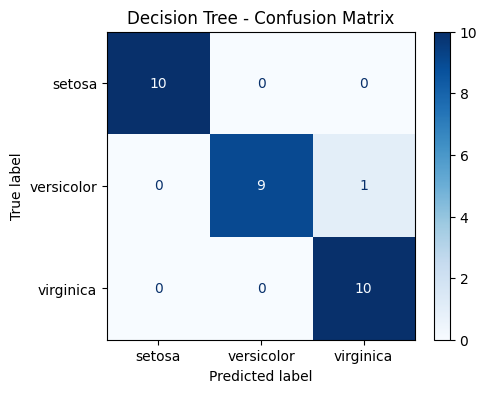

In [5]:
print(classification_report(y_test, tree_predictions, target_names=iris.target_names))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, tree_predictions,
    display_labels=iris.target_names,
    cmap='Blues',
    ax=ax
)
ax.set_title('Decision Tree - Confusion Matrix')
plt.show()

## 6. Visualise the learned Decision Tree

Each internal box is a question about one feature. `gini` describes how mixed the classes are at that node; a lower value means a purer node. A leaf gives the final predicted class.

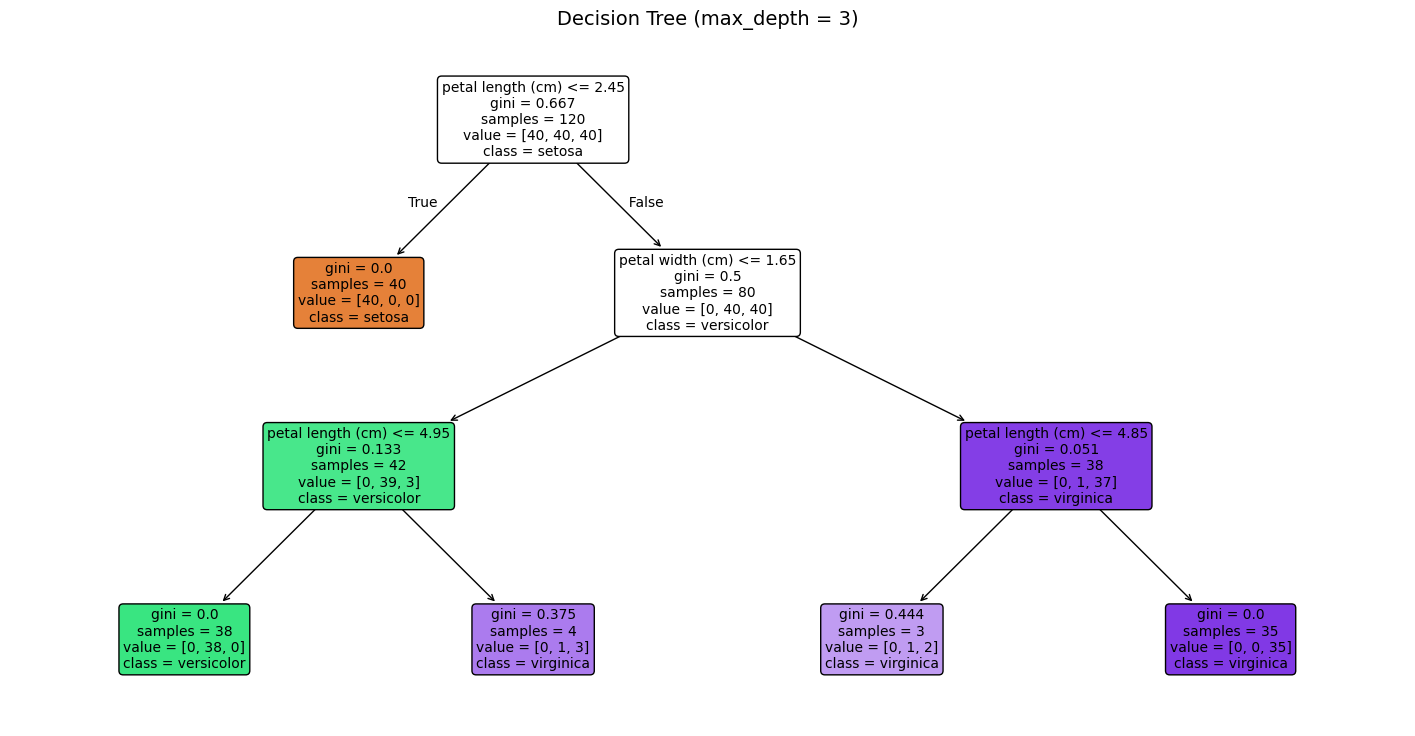

In [6]:
plt.figure(figsize=(18, 9))
plot_tree(
    tree_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree (max_depth = 3)', fontsize=14)
plt.show()

## 7. Train a Random Forest

A Random Forest trains many decision trees on different bootstrap samples and combines their predictions by majority vote. This usually gives a more stable model than relying on one tree.

I use 200 trees. More trees generally make the result more stable, but they also require more computation.

In [7]:
forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_accuracy = accuracy_score(y_test, forest_predictions)
print(f'Random Forest test accuracy: {forest_accuracy:.3f}')

Random Forest test accuracy: 0.900


## 8. Evaluate and compare both models

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



,Model,Test accuracy
0,Decision Tree,0.967
1,Random Forest,0.900


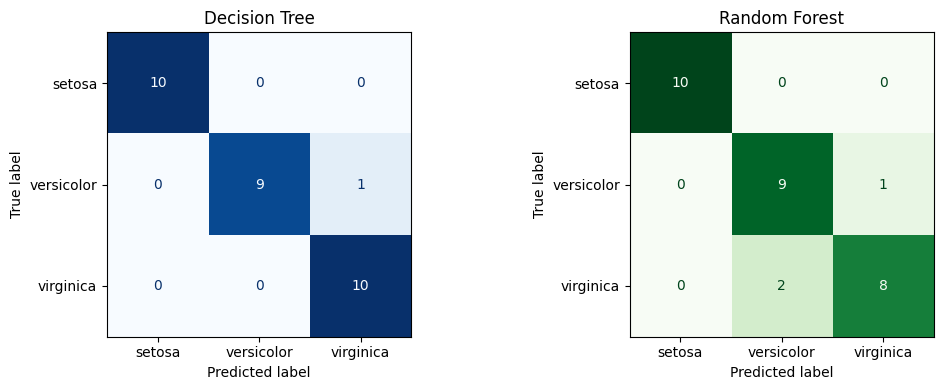

In [8]:
print(classification_report(y_test, forest_predictions, target_names=iris.target_names))

results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Test accuracy': [tree_accuracy, forest_accuracy]
})
display(results.style.format({'Test accuracy': '{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, tree_predictions, display_labels=iris.target_names,
    cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Decision Tree')

ConfusionMatrixDisplay.from_predictions(
    y_test, forest_predictions, display_labels=iris.target_names,
    cmap='Greens', ax=axes[1], colorbar=False
)
axes[1].set_title('Random Forest')

plt.tight_layout()
plt.show()

## 9. Feature importance

Both models can estimate feature importance. A higher value means that the feature was more useful for reducing impurity across the splits. Importance does not prove a causal relationship.

,Decision Tree,Random Forest
feature,,
petal length (cm),0.579077,0.453793
petal width (cm),0.420923,0.412449
sepal length (cm),0.000000,0.115873
sepal width (cm),0.000000,0.017885


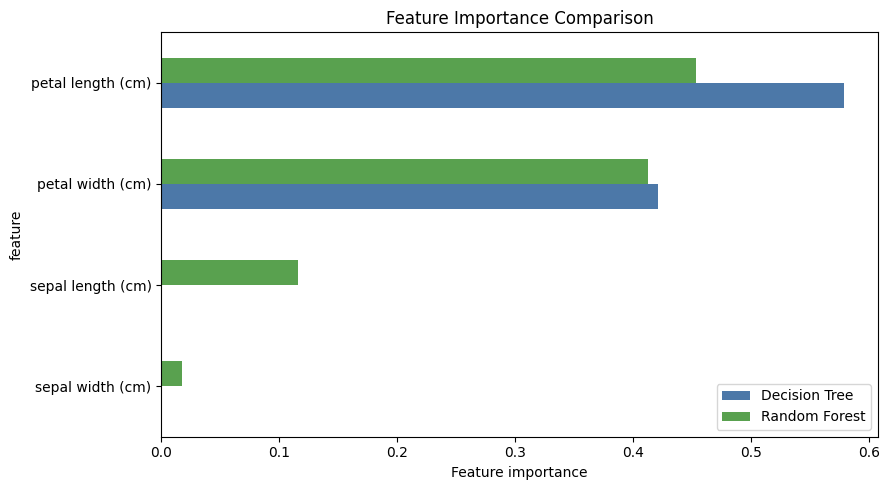

In [9]:
importance = pd.DataFrame({
    'feature': iris.feature_names,
    'Decision Tree': tree_model.feature_importances_,
    'Random Forest': forest_model.feature_importances_
}).set_index('feature').sort_values('Random Forest')

display(importance.sort_values('Random Forest', ascending=False))

importance.plot(kind='barh', figsize=(9, 5), color=['#4C78A8', '#59A14F'])
plt.xlabel('Feature importance')
plt.title('Feature Importance Comparison')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Key points

- A Decision Tree is easy to explain because it makes explicit rules.
- Limiting tree depth is one way to reduce overfitting.
- A Random Forest combines many trees and is usually more stable.
- Use the test set only for final evaluation; do not use it to fit the models.
- For a larger project, tune parameters such as `max_depth`, `min_samples_leaf`, and `n_estimators` using cross-validation.